# Explainable AI Analysis: Hospital Readmission Prediction

This project applies **Explainable AI (XAI) methods** to a hospital readmission prediction task. Using XGBoost as the base classifier, we analyze which patient features drive readmission risk through **eli5 Permutation Importance** and **SHAP values**, then use these insights for XAI-guided feature selection.

**Dataset**: 25,000 records of diabetic patients from US hospitals, with 64 features covering clinical complexity, treatment details, and demographics. Target: hospital readmission (binary classification, 54/46 split).

## 2. Setup & Data Loading

In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

# Evaluation
from sklearn.model_selection import cross_val_score

# XAI Tools
from eli5.sklearn import PermutationImportance
import shap

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Settings
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
np.random.seed(42)

print("All libraries imported successfully")

2026-02-16 18:11:57.483573: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


All libraries imported successfully


In [2]:
# Load dataset with error handling
try:
    df = pd.read_csv('hospital_readmissions.csv')
    print(f"✓ Dataset loaded successfully")
    print(f"  Shape: {df.shape}")
    print(f"  Features: {df.shape[1] - 1}")
    print(f"  Samples: {df.shape[0]}")
except FileNotFoundError:
    print("ERROR: File 'hospital_readmissions.csv' not found in current directory.")
    print("Please ensure the CSV file is in the same folder as this notebook.")
    raise
except Exception as e:
    print(f"ERROR: Failed to load dataset: {str(e)}")
    raise

✓ Dataset loaded successfully
  Shape: (25000, 65)
  Features: 64
  Samples: 25000


In [3]:
# Display basic information
print("First 5 rows:")
display(df.head())

print("\nDataset Info:")
df.info()

First 5 rows:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race_Caucasian,race_AfricanAmerican,...,citoglipton_No,insulin_No,glyburide-metformin_No,glipizide-metformin_No,glimepiride-pioglitazone_No,metformin-rosiglitazone_No,metformin-pioglitazone_No,change_No,diabetesMed_Yes,readmitted
0,14,41,0,11,0,0,0,6,True,False,...,True,True,True,True,True,True,True,True,True,0
1,2,30,0,12,0,0,1,9,True,False,...,True,False,True,True,True,True,True,False,True,1
2,5,66,0,22,1,0,2,9,True,False,...,True,True,True,True,True,True,True,True,True,1
3,3,63,0,8,0,0,0,8,True,False,...,True,True,True,True,True,True,True,True,True,1
4,5,40,0,6,0,0,1,9,True,False,...,True,True,True,True,True,True,True,True,False,0



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 65 columns):
 #   Column                                    Non-Null Count  Dtype
---  ------                                    --------------  -----
 0   time_in_hospital                          25000 non-null  int64
 1   num_lab_procedures                        25000 non-null  int64
 2   num_procedures                            25000 non-null  int64
 3   num_medications                           25000 non-null  int64
 4   number_outpatient                         25000 non-null  int64
 5   number_emergency                          25000 non-null  int64
 6   number_inpatient                          25000 non-null  int64
 7   number_diagnoses                          25000 non-null  int64
 8   race_Caucasian                            25000 non-null  bool 
 9   race_AfricanAmerican                      25000 non-null  bool 
 10  gender_Female                             2

In [4]:
# Check for missing values
missing_values = df.isnull().sum().sum()
print(f"Missing values: {missing_values}")

Missing values: 0


## 3. Exploratory Data Analysis

### 3.1 Target Distribution


Target distribution:
readmitted
0    13590
1    11410
Name: count, dtype: int64

Class balance: 54.4% (0) vs 45.6% (1)
The dataset is moderately imbalanced (54.4% vs 45.6%),but manageable without resampling.


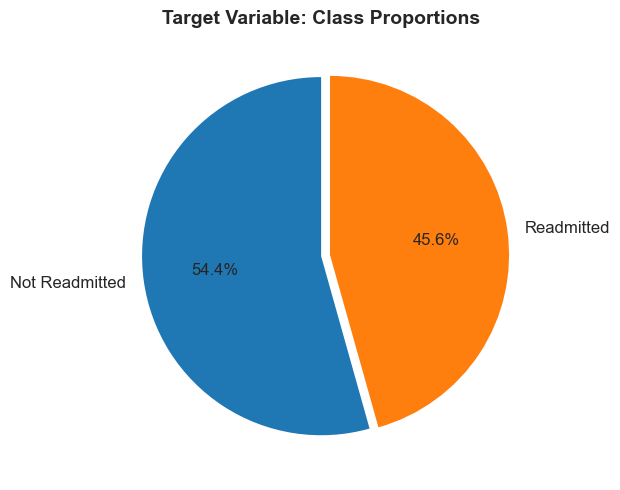

In [5]:
# Check target distribution
print("\nTarget distribution:")
target_counts = df['readmitted'].value_counts()
print(target_counts)
print(f"\nClass balance: {target_counts[0]/len(df)*100:.1f}% (0) vs {target_counts[1]/len(df)*100:.1f}% (1)")

print("The dataset is moderately imbalanced (54.4% vs 45.6%),but manageable without resampling.")

# Pie chart
fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(target_counts.values, labels=['Not Readmitted', 'Readmitted'],
       autopct='%1.1f%%', startangle=90,
       explode=(0, 0.05), textprops={'fontsize': 12})
ax.set_title('Target Variable: Class Proportions', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### 3.2 Statistics and Distributions of Numerical Features

Descriptive Statistics - Numerical Features:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00
mean,4.40,42.96,1.34,15.99,0.37,0.20,0.64,7.42
std,2.99,19.77,1.71,8.11,1.22,0.98,1.26,1.94
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
25%,2.00,31.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
max,14.00,126.00,6.00,81.00,36.00,64.00,21.00,16.00


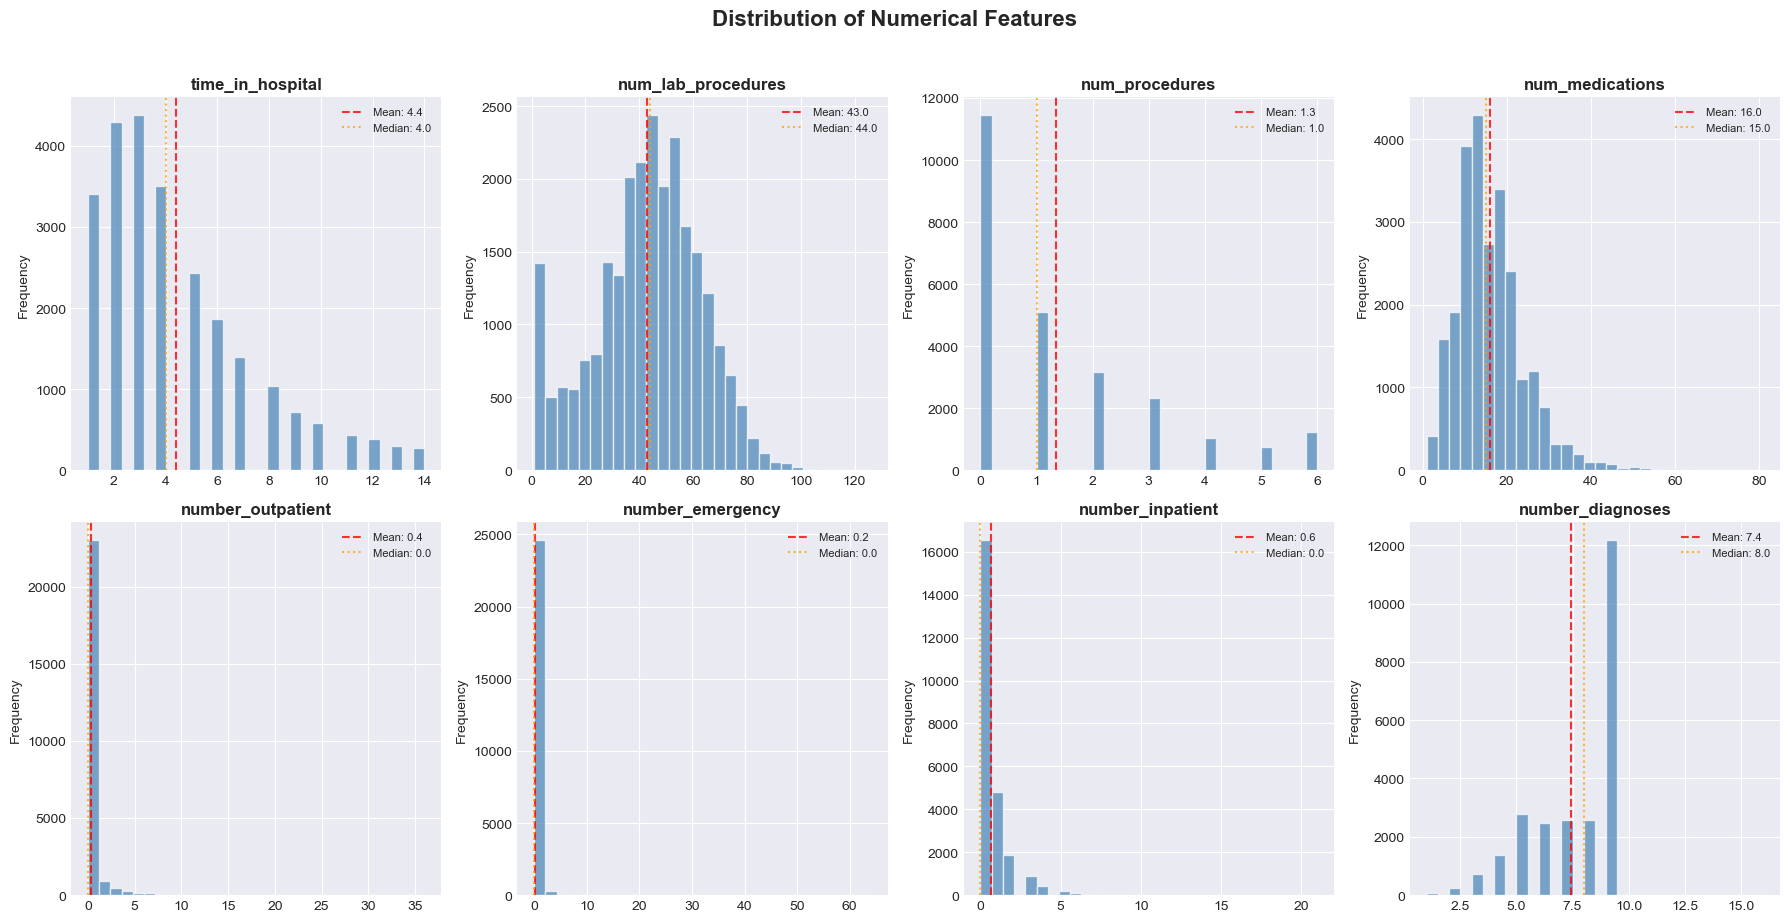

In [6]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.drop('readmitted')

print("Descriptive Statistics - Numerical Features:")
print("=" * 90)
display(df[numerical_cols].describe().round(2))

# Histograms for all numerical features
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    axes[idx].hist(df[col], bins=30, color='steelblue', alpha=0.7, edgecolor='white')
    axes[idx].set_title(col, fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('Frequency')
    mean_val = df[col].mean()
    median_val = df[col].median()
    axes[idx].axvline(mean_val, color='red', linestyle='--', alpha=0.8, label=f'Mean: {mean_val:.1f}')
    axes[idx].axvline(median_val, color='orange', linestyle=':', alpha=0.8, label=f'Median: {median_val:.1f}')
    axes[idx].legend(fontsize=8)

plt.suptitle('Distribution of Numerical Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.3 Correlation Analysis

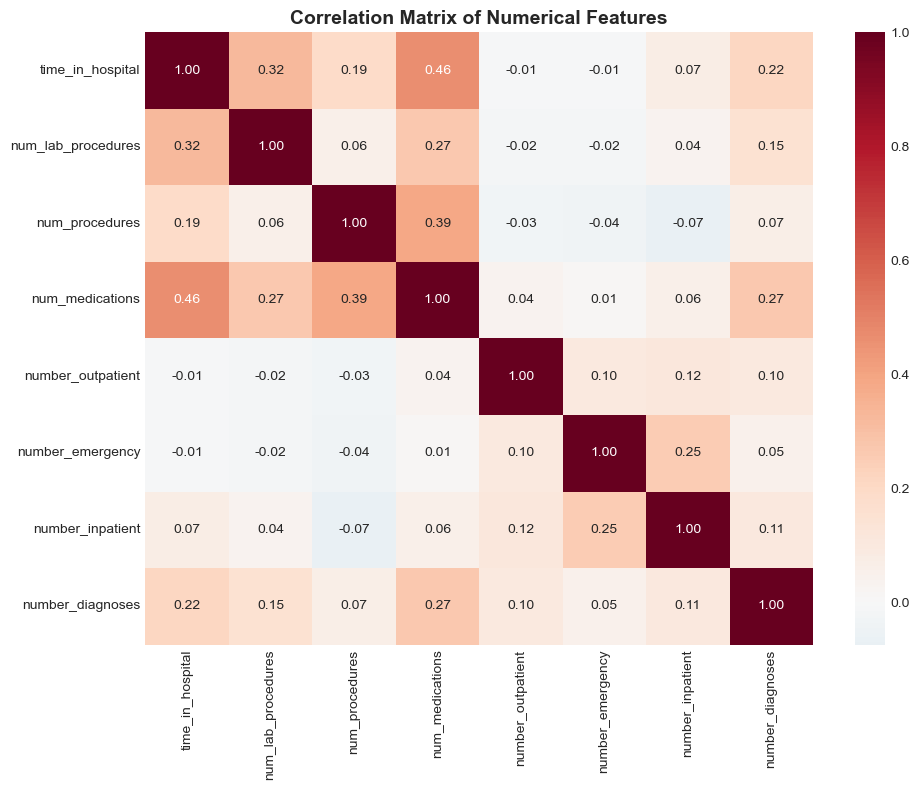

Strongest correlations (|r| > 0.3):
  time_in_hospital <-> num_lab_procedures: r = 0.325
  time_in_hospital <-> num_medications: r = 0.462
  num_procedures <-> num_medications: r = 0.390


In [7]:
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0)
plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Highlight strongest correlations
print("Strongest correlations (|r| > 0.3):")
for i in range(len(corr_matrix)):
    for j in range(i+1, len(corr_matrix)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.3:
            print(f"  {corr_matrix.index[i]} <-> {corr_matrix.columns[j]}: r = {r:.3f}")

### 3.4 Numerical Feature Distribution by Readmission Status

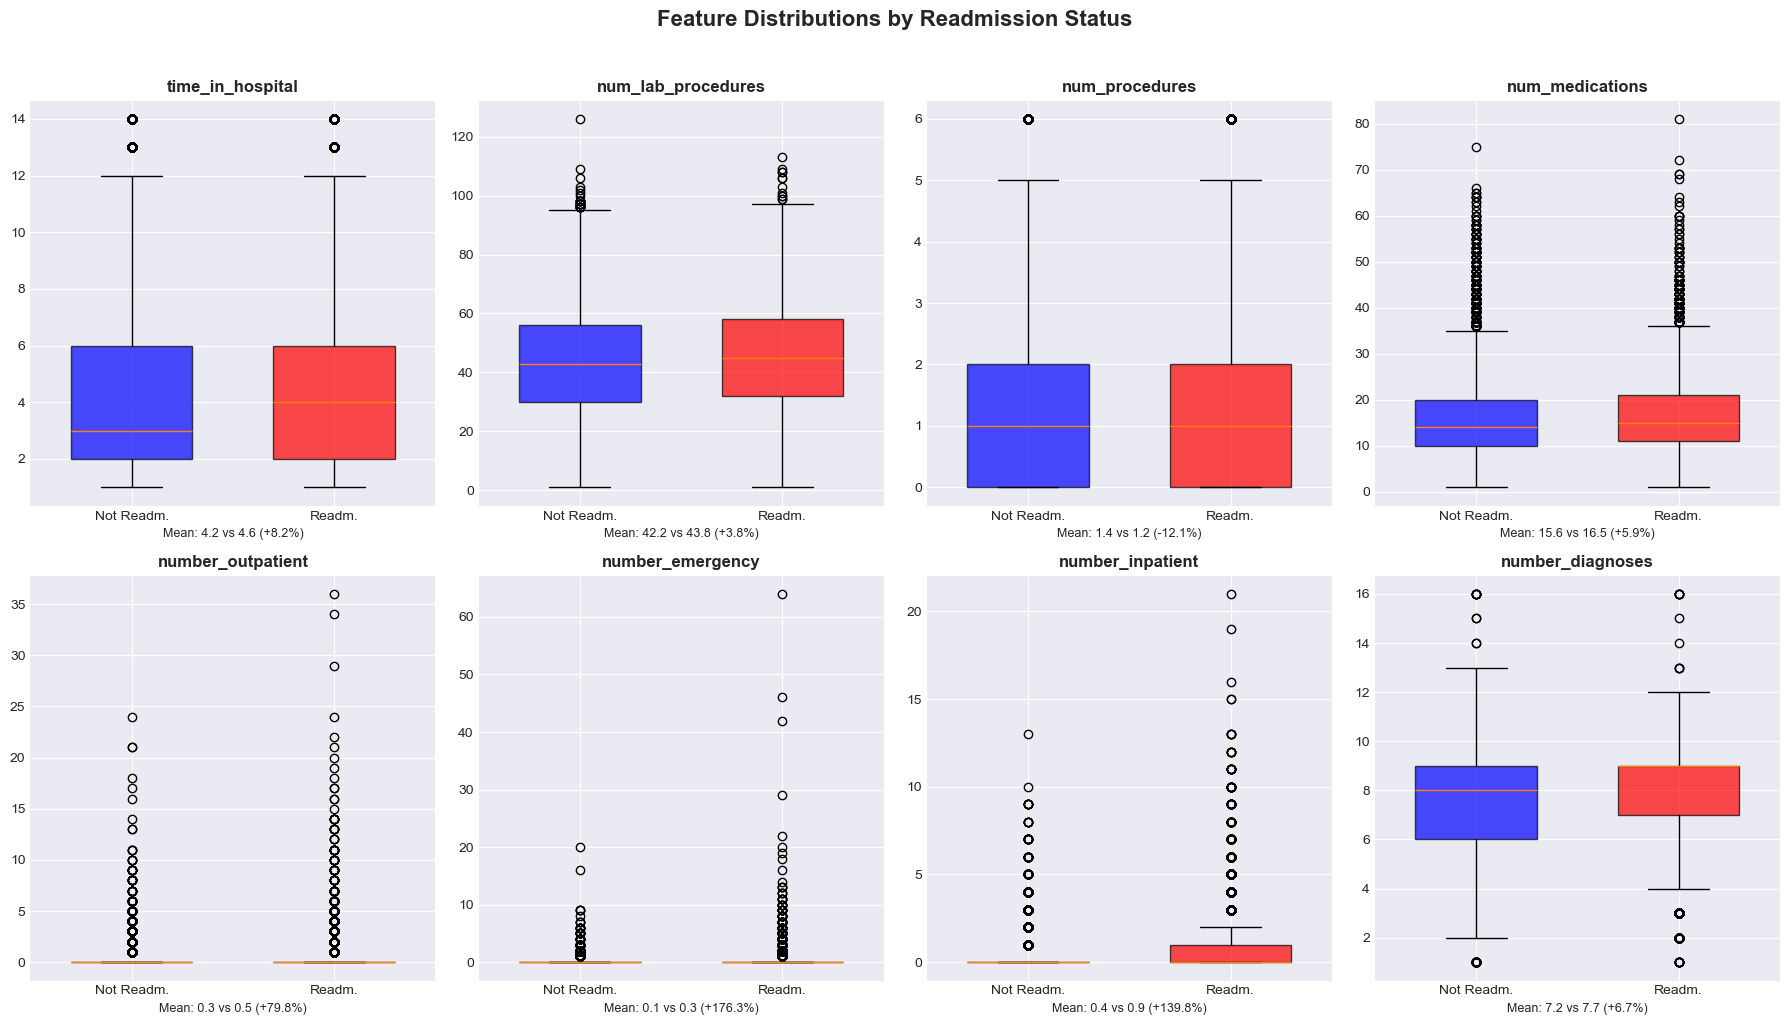

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    data_0 = df.loc[df['readmitted'] == 0, col]
    data_1 = df.loc[df['readmitted'] == 1, col]
    
    bp = axes[idx].boxplot([data_0, data_1], labels=['Not Readm.', 'Readm.'],
                           patch_artist=True, widths=0.6)
    bp['boxes'][0].set_facecolor('blue')
    bp['boxes'][1].set_facecolor('red')
    for box in bp['boxes']:
        box.set_alpha(0.7)
    
    # Title with mean difference
    mean_0 = data_0.mean()
    mean_1 = data_1.mean()
    diff_pct = (mean_1 - mean_0) / mean_0 * 100 if mean_0 != 0 else 0
    axes[idx].set_title(f'{col}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(f'Mean: {mean_0:.1f} vs {mean_1:.1f} ({diff_pct:+.1f}%)', fontsize=9)

plt.suptitle('Feature Distributions by Readmission Status', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Key Findings from Box Plots:**
- **number_inpatient** shows a very clear class separation — readmitted patients have significantly more prior inpatient stays, telling us this as one of the strongest predictor.
- **number_emergency** and **number_outpatient** also shift upward for readmitted patients, indicating that high healthcare utilization is a consistent risk signal.
- **num_medications**, **num_lab_procedures**, and **number_diagnoses** show subtle but consistent increases for readmitted patients, reflecting higher clinical complexity.
- **time_in_hospital** and **num_procedures** show minimal differences between classes, suggesting limited predictive value on their own.

### 3.5 Readmission Rates of Categorical Features

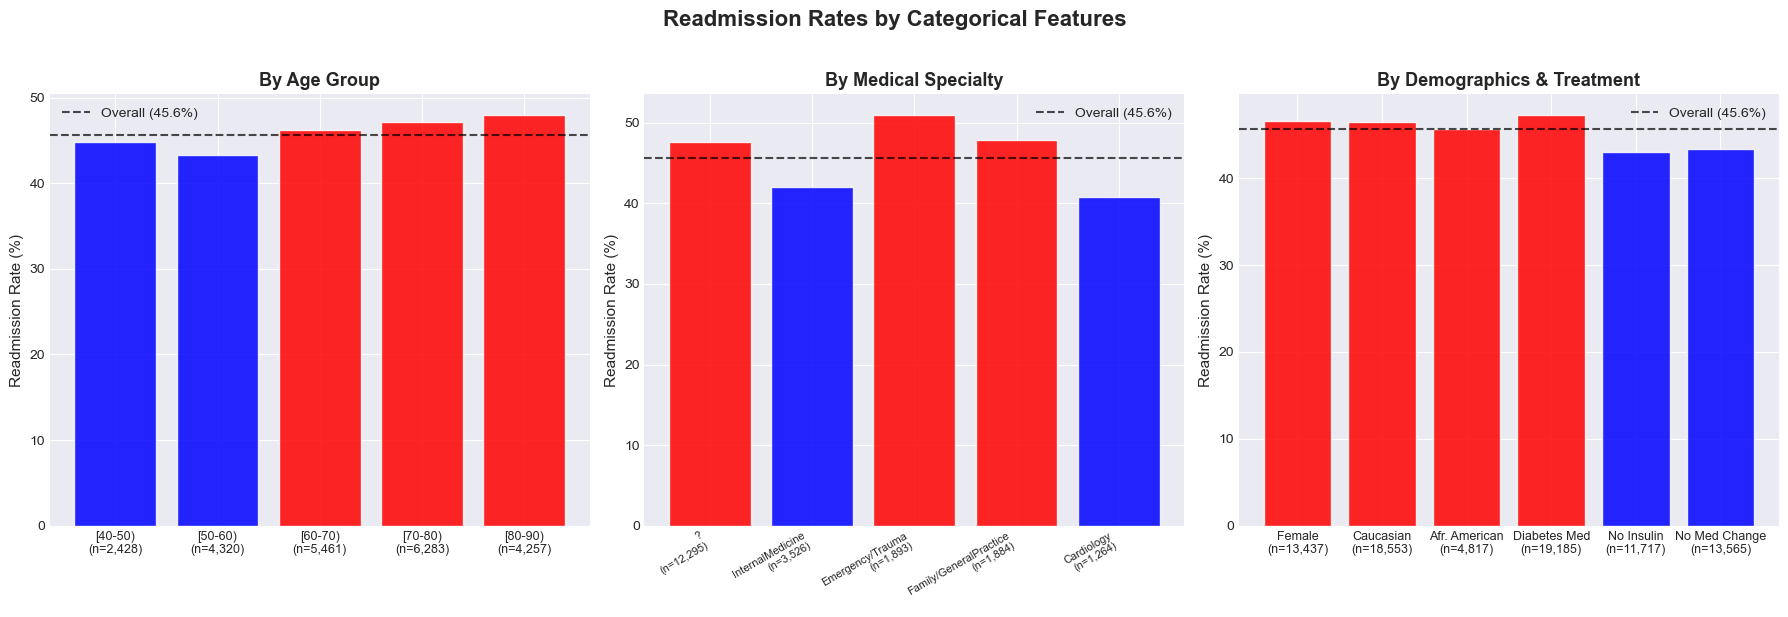

Red = above-average readmission rate | Blue = below-average | Dashed line = overall rate


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
overall_rate = df['readmitted'].mean() * 100

# --- Age Groups ---
age_cols = sorted([col for col in df.columns if col.startswith('age_')])
age_labels, age_rates, age_n = [], [], []
for col in age_cols:
    mask = df[col]
    age_labels.append(col.replace('age_', ''))
    age_rates.append(df.loc[mask, 'readmitted'].mean() * 100)
    age_n.append(mask.sum())

colors = ['red' if r > overall_rate else 'blue' for r in age_rates]
axes[0].bar(range(len(age_labels)), age_rates, color=colors, alpha=0.85, edgecolor='white')
axes[0].set_xticks(range(len(age_labels)))
axes[0].set_xticklabels([f"{l}\n(n={n:,})" for l, n in zip(age_labels, age_n)], fontsize=9)
axes[0].axhline(y=overall_rate, color='black', linestyle='--', alpha=0.7, label=f'Overall ({overall_rate:.1f}%)')
axes[0].set_title('By Age Group', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Readmission Rate (%)', fontsize=11)
axes[0].legend()

# --- Medical Specialty ---
spec_cols = [col for col in df.columns if col.startswith('medical_specialty_')]
spec_labels, spec_rates, spec_n = [], [], []
for col in spec_cols:
    mask = df[col]
    spec_labels.append(col.replace('medical_specialty_', ''))
    spec_rates.append(df.loc[mask, 'readmitted'].mean() * 100)
    spec_n.append(mask.sum())

colors = ['red' if r > overall_rate else 'blue' for r in spec_rates]
axes[1].bar(range(len(spec_labels)), spec_rates, color=colors, alpha=0.85, edgecolor='white')
axes[1].set_xticks(range(len(spec_labels)))
axes[1].set_xticklabels([f"{l}\n(n={n:,})" for l, n in zip(spec_labels, spec_n)], fontsize=8, rotation=30, ha='right')
axes[1].axhline(y=overall_rate, color='black', linestyle='--', alpha=0.7, label=f'Overall ({overall_rate:.1f}%)')
axes[1].set_title('By Medical Specialty', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Readmission Rate (%)', fontsize=11)
axes[1].legend()

# --- Key Binary Features ---
binary_features = [
    ('Female', 'gender_Female'),
    ('Caucasian', 'race_Caucasian'),
    ('Afr. American', 'race_AfricanAmerican'),
    ('Diabetes Med', 'diabetesMed_Yes'),
    ('No Insulin', 'insulin_No'),
    ('No Med Change', 'change_No'),
]
bin_labels, bin_rates, bin_n = [], [], []
for label, col in binary_features:
    if col in df.columns:
        mask = df[col]
        bin_labels.append(label)
        bin_rates.append(df.loc[mask, 'readmitted'].mean() * 100)
        bin_n.append(mask.sum())

colors = ['red' if r > overall_rate else 'blue' for r in bin_rates]
axes[2].bar(range(len(bin_labels)), bin_rates, color=colors, alpha=0.85, edgecolor='white')
axes[2].set_xticks(range(len(bin_labels)))
axes[2].set_xticklabels([f"{l}\n(n={n:,})" for l, n in zip(bin_labels, bin_n)], fontsize=9)
axes[2].axhline(y=overall_rate, color='black', linestyle='--', alpha=0.7, label=f'Overall ({overall_rate:.1f}%)')
axes[2].set_title('By Demographics & Treatment', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Readmission Rate (%)', fontsize=11)
axes[2].legend()

plt.suptitle('Readmission Rates by Categorical Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Red = above-average readmission rate | Blue = below-average | Dashed line = overall rate")

### Key EDA Observations

1. **Target**: Moderately imbalanced (54/46), manageable without resampling
2. **Utilization features** (`number_inpatient`, `number_emergency`, `number_outpatient`) are heavily right-skewed — most patients have 0 prior visits, but a high-utilization subgroup likely represents chronic patients
3. **Strongest correlation**: `num_medications` and `time_in_hospital` (clinically intuitive — longer stays involve more medications)
4. **Best class separator**: `number_inpatient` shows the clearest difference between readmitted and non-readmitted patients
5. **Categorical features**: Readmission rates vary by age group and specialty, while demographics (race, gender) show minimal differences

## 4. Data Preprocessing

### 4.1 Separate Features and Target

In [10]:
# Separate features (X) and target (y)
X = df.drop('readmitted', axis=1)
y = df['readmitted']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (25000, 64)
Target shape: (25000,)


### 4.2 Feature Selection: Variance Threshold

Remove features with very low variance (quasi-constant features that provide little information).

In [11]:
# Check variance of all features
print("Feature variances (sorted, lowest first):")
variances = X.var().sort_values()
print(variances.head(15))

# Count features with very low variance (< 0.01)
low_variance_count = (variances < 0.01).sum()
print(f"\nFeatures with variance < 0.01: {low_variance_count}")

Feature variances (sorted, lowest first):
examide_No                     0.000000
citoglipton_No                 0.000000
metformin-rosiglitazone_No     0.000000
metformin-pioglitazone_No      0.000000
acetohexamide_No               0.000000
troglitazone_No                0.000040
glimepiride-pioglitazone_No    0.000040
glipizide-metformin_No         0.000160
tolbutamide_No                 0.000240
miglitol_No                    0.000400
tolazamide_No                  0.000440
chlorpropamide_No              0.000720
acarbose_No                    0.002792
glyburide-metformin_No         0.006320
nateglinide_No                 0.007346
dtype: float64

Features with variance < 0.01: 15


In [12]:
# Apply Variance Threshold
# Threshold of 0.01: Remove features where >99% of values are the same
variance_selector = VarianceThreshold(threshold=0.01)
X_filtered = variance_selector.fit_transform(X)

# Get feature names after filtering
selected_features = X.columns[variance_selector.get_support()]
removed_features = X.columns[~variance_selector.get_support()]

print(f"Original features: {X.shape[1]}")
print(f"Features after variance threshold: {X_filtered.shape[1]}")
print(f"Removed features: {len(removed_features)}")

print("\nRemoved features (low variance):")
for feat in removed_features:
    print(f"  - {feat}")

# Convert back to DataFrame for easier handling
X_filtered = pd.DataFrame(X_filtered, columns=selected_features)
display(X_filtered.head())

Original features: 64
Features after variance threshold: 49
Removed features: 15

Removed features (low variance):
  - nateglinide_No
  - chlorpropamide_No
  - acetohexamide_No
  - tolbutamide_No
  - acarbose_No
  - miglitol_No
  - troglitazone_No
  - tolazamide_No
  - examide_No
  - citoglipton_No
  - glyburide-metformin_No
  - glipizide-metformin_No
  - glimepiride-pioglitazone_No
  - metformin-rosiglitazone_No
  - metformin-pioglitazone_No


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race_Caucasian,race_AfricanAmerican,...,metformin_No,repaglinide_No,glimepiride_No,glipizide_No,glyburide_No,pioglitazone_No,rosiglitazone_No,insulin_No,change_No,diabetesMed_Yes
0,14,41,0,11,0,0,0,6,1,0,...,1,1,1,0,1,1,1,1,1,1
1,2,30,0,12,0,0,1,9,1,0,...,1,1,1,1,1,0,1,0,0,1
2,5,66,0,22,1,0,2,9,1,0,...,0,1,1,1,1,1,1,1,1,1
3,3,63,0,8,0,0,0,8,1,0,...,1,1,1,1,0,1,1,1,1,1
4,5,40,0,6,0,0,1,9,1,0,...,1,1,1,1,1,1,1,1,1,0


### 4.3 Train-Test Split with Stratification

Split data into training (80%) and test (20%) sets while maintaining the same class distribution in both sets.

In [13]:
# Split with stratification to maintain class balance
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Verify stratification worked
print("\nClass distribution in training set:")
print(y_train.value_counts(normalize=True))
print("\nClass distribution in test set:")
print(y_test.value_counts(normalize=True))

Training set: 20000 samples
Test set: 5000 samples

Class distribution in training set:
readmitted
0    0.5436
1    0.4564
Name: proportion, dtype: float64

Class distribution in test set:
readmitted
0    0.5436
1    0.4564
Name: proportion, dtype: float64


### 4.4 Fix Feature Names for XGBoost

In [14]:
# Fix feature names for XGBoost compatibility
# XGBoost doesn't accept [, ], < in feature names
def clean_feature_names(df):
    """Remove special characters from feature names that XGBoost doesn't accept"""
    new_columns = []
    for col in df.columns:
        new_col = col.replace('[', '').replace(']', '').replace('<', '').replace('(','').replace(')','')
        new_columns.append(new_col)
    return new_columns

# Apply to both train and test sets
X_train.columns = clean_feature_names(X_train)
X_test.columns = clean_feature_names(X_test)
X_filtered.columns = clean_feature_names(X_filtered)

print("Feature names cleaned for XGBoost compatibility")
print(f"Example: 'age_[70-80)' → '{X_train.columns[X_train.columns.str.contains('age_70')][0] if any(X_train.columns.str.contains('age_70')) else 'age_70-80)'}'")


Feature names cleaned for XGBoost compatibility
Example: 'age_[70-80)' → 'age_70-80'


### Summary
- Variance Threshold removed 15 quasi-constant features (64 to 49)
- Stratified 80/20 train-test split
- Feature names cleaned for XGBoost compatibility
- No scaling applied (tree-based model)

## 5. Feature Engineering

The EDA revealed that `number_inpatient`, `number_emergency`, and `number_outpatient` are the strongest individual predictors of readmission. We combine them into a single utilization score and create ratio features to capture treatment intensity per day.


### 5.1 New Feature which Combines the Three Most Important Features

In [15]:
X_train['total_utilization'] = (X_train['number_inpatient'] 
                              + X_train['number_emergency'] 
                              + X_train['number_outpatient'])
X_test['total_utilization'] = (X_test['number_inpatient'] 
                             + X_test['number_emergency'] 
                             + X_test['number_outpatient'])

### 5.2 New Ratio Feature for Treatment Intensity per Day

In [16]:
X_train['meds_per_day'] = X_train['num_medications'] / X_train['time_in_hospital']
X_test['meds_per_day'] = X_test['num_medications'] / X_test['time_in_hospital']

X_train['labs_per_day'] = X_train['num_lab_procedures'] / X_train['time_in_hospital']
X_test['labs_per_day'] = X_test['num_lab_procedures'] / X_test['time_in_hospital']

### 5.3 Overview of the New Features

In [17]:
print(f"Feature count: {X_train.shape[1]}")
print(f"\nNew feature statistics (training set):")
display(X_train[['total_utilization', 'meds_per_day', 'labs_per_day']].describe().round(2))

Feature count: 52

New feature statistics (training set):


,total_utilization,meds_per_day,labs_per_day
count,20000.00,20000.00,20000.00
mean,1.22,5.06,14.21
std,2.34,3.79,11.82
min,0.00,0.17,0.07
25%,0.00,2.60,6.50
50%,0.00,4.00,10.83
75%,2.00,6.17,18.00
max,68.00,42.00,95.00


## 6. Model Training and Evaluation

### 6.1 Train a Baseline as a Reference

In [18]:
# Initialize XGBoost Classifier
model_baseline = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    base_score=0.5
)

print("Training XGBoost model...")
model_baseline.fit(X_train, y_train)
print("Model trained successfully")

Training XGBoost model...
Model trained successfully


### 6.2 Short Evaluation of the Baseline

In [19]:
# Crossvalidation to check stability
cv_scores = cross_val_score(model_baseline, X_train, y_train, cv=5, scoring='f1')
print(f"5-Fold CV F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

5-Fold CV F1: 0.5517 (+/- 0.0109)


In [20]:
# Make predictions
y_pred_train = model_baseline.predict(X_train)
y_pred_test = model_baseline.predict(X_test)

# probability for 1 of every row (less than 0.5 if prediction is 0, else more than 0.5)
y_pred_proba_test = model_baseline.predict_proba(X_test)[:, 1]

print("Predictions generated successfully")

Predictions generated successfully


In [21]:
# Calculate metrics for both train and test
def calculate_metrics(y_true, y_pred, y_proba=None):
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }
    if y_proba is not None:
        metrics['ROC-AUC'] = roc_auc_score(y_true, y_proba)
    return metrics

# Compare metrics of train and test set to check overfitting
def compare_train_test_performance(
    y_pred_train, y_pred_test, y_pred_proba_test,
    y_train, y_test, model_name="Performance Model X"):
    """Shows a comparison of the metrics on the train
    and test data set to check overfitting."""
    train_metrics = calculate_metrics(y_train, y_pred_train)
    test_metrics = calculate_metrics(y_test, y_pred_test, y_pred_proba_test)

    print("=" * 60)
    print(model_name)
    print("=" * 60)
    print(f"\n{'Metric':<15} {'Training':<15} {'Test':<15}")
    print("-" * 60)
    for metric in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
        print(f"{metric:<15} {train_metrics[metric]:<15.4f} {test_metrics[metric]:<15.4f}")
    print(f"{'ROC-AUC':<15} {'-':<15} {test_metrics['ROC-AUC']:<15.4f}")
    print("\n")

In [22]:
compare_train_test_performance(
    y_pred_train, y_pred_test, y_pred_proba_test,
    y_train, y_test,
    model_name="Baseline Model")

Baseline Model

Metric          Training        Test           
------------------------------------------------------------
Accuracy        0.8243          0.6190         
Precision       0.8568          0.5980         
Recall          0.7383          0.5039         
F1-Score        0.7932          0.5470         
ROC-AUC         -               0.6579         




### 6.3 Hyperparameter Tuning (RandomizedSearchCV)

RandomizedSearchCV samples random parameter combinations, making it more efficient than GridSearchCV for large search spaces while still finding competitive hyperparameters.

In [23]:
# Define parameter search space
param_distributions = {
    'max_depth': [3, 4, 5, 6, 7, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'n_estimators': [100, 150, 200, 300],
    'subsample': [0.6, 0.7, 0.8, 0.9],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9],
    'min_child_weight': [1, 3, 5, 7],
    'reg_alpha': [0, 0.1, 0.5, 1.0],
    'reg_lambda': [0.5, 1.0, 2.0, 5.0],
}

# RandomizedSearchCV: 200 random combinations × 3 folds = 600 fits
random_search = RandomizedSearchCV(
    XGBClassifier(random_state=42),
    param_distributions=param_distributions,
    n_iter=200,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print(f"\nBest F1 Score (CV): {random_search.best_score_:.4f}")
print(f"\nBest Parameters:")
for param, value in random_search.best_params_.items():
    print(f"  {param}= {value},")

Fitting 3 folds for each of 200 candidates, totalling 600 fits

Best F1 Score (CV): 0.5584

Best Parameters:
  subsample= 0.8,
  reg_lambda= 0.5,
  reg_alpha= 0.1,
  n_estimators= 300,
  min_child_weight= 3,
  max_depth= 5,
  learning_rate= 0.1,
  colsample_bytree= 0.8,


In [24]:
# Use the best model from tuning as our tuned model
model_tuned = random_search.best_estimator_

In [25]:
# Make predictions
y_pred_train_tuned = model_tuned.predict(X_train)
y_pred_test_tuned = model_tuned.predict(X_test)

# probability for 1 of every row (less than 0.5 if prediction is 0, else more than 0.5)
y_pred_proba_test_tuned = model_tuned.predict_proba(X_test)[:, 1]

print("Predictions generated successfully")

Predictions generated successfully


### 6.4 Compare Performance of Tuned Model with Baseline

In [26]:
# Crossvalidation to check stability
cv_scores_tuned = cross_val_score(model_tuned, X_train, y_train, cv=5, scoring='f1')
print(f"5-Fold CV F1: {cv_scores_tuned.mean():.4f} (+/- {cv_scores_tuned.std():.4f})")

5-Fold CV F1: 0.5561 (+/- 0.0086)


In [27]:
compare_train_test_performance(y_pred_train_tuned,y_pred_test_tuned, y_pred_proba_test_tuned, y_train, y_test, model_name="TUNED MODEL")

TUNED MODEL

Metric          Training        Test           
------------------------------------------------------------
Accuracy        0.7476          0.6212         
Precision       0.7588          0.5991         
Recall          0.6551          0.5140         
F1-Score        0.7032          0.5533         
ROC-AUC         -               0.6603         




**Key finding**: The overfitting got a little less strong, but is still significant

In [28]:
def compare_two_models(metrics_1, metrics_2, name_1="Model 1", name_2="Model 2"):
    """ Shows a comparison of the performance of to models, both as table and plot. """
    
    metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

    comparison_table = pd.DataFrame({
        'Metric': metrics_to_plot,
        name_1: [metrics_1[m] for m in metrics_to_plot],
        name_2: [metrics_2[m] for m in metrics_to_plot],
    })
    comparison_table['Difference'] = comparison_table[name_2] - comparison_table[name_1]
    comparison_table['Change (%)'] = (comparison_table['Difference'] / comparison_table[name_1]) * 100

    print("\n" + "=" * 90)
    print(f"MODEL PERFORMANCE COMPARISON: {name_1.upper()} vs {name_2.upper()}")
    print("=" * 90)
    display(comparison_table.round(2))
    print("=" * 90)

    # Bar chart
    values_1 = [metrics_1[m] for m in metrics_to_plot]
    values_2 = [metrics_2[m] for m in metrics_to_plot]
    x = np.arange(len(metrics_to_plot))
    width = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))
    bars1 = ax.bar(x - width/2, values_1, width, label=name_1, color='steelblue', alpha=0.8)
    bars2 = ax.bar(x + width/2, values_2, width, label=name_2, color='coral', alpha=0.8)

    ax.set_ylabel('Score', fontsize=12)
    ax.set_xlabel('Metric', fontsize=12)
    ax.set_title(f'Performance Comparison: {name_1} vs {name_2}', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_to_plot)
    ax.legend()
    ax.set_ylim([0.0, 0.8])
    ax.grid(axis='y', alpha=0.3)

    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()


MODEL PERFORMANCE COMPARISON: BASELINE MODEL vs TUNED MODEL


,Metric,Baseline Model,Tuned Model,Difference,Change (%)
0,Accuracy,0.62,0.62,0.00,0.36
1,Precision,0.60,0.60,0.00,0.18
2,Recall,0.50,0.51,0.01,2.00
3,F1-Score,0.55,0.55,0.01,1.16
4,ROC-AUC,0.66,0.66,0.00,0.36


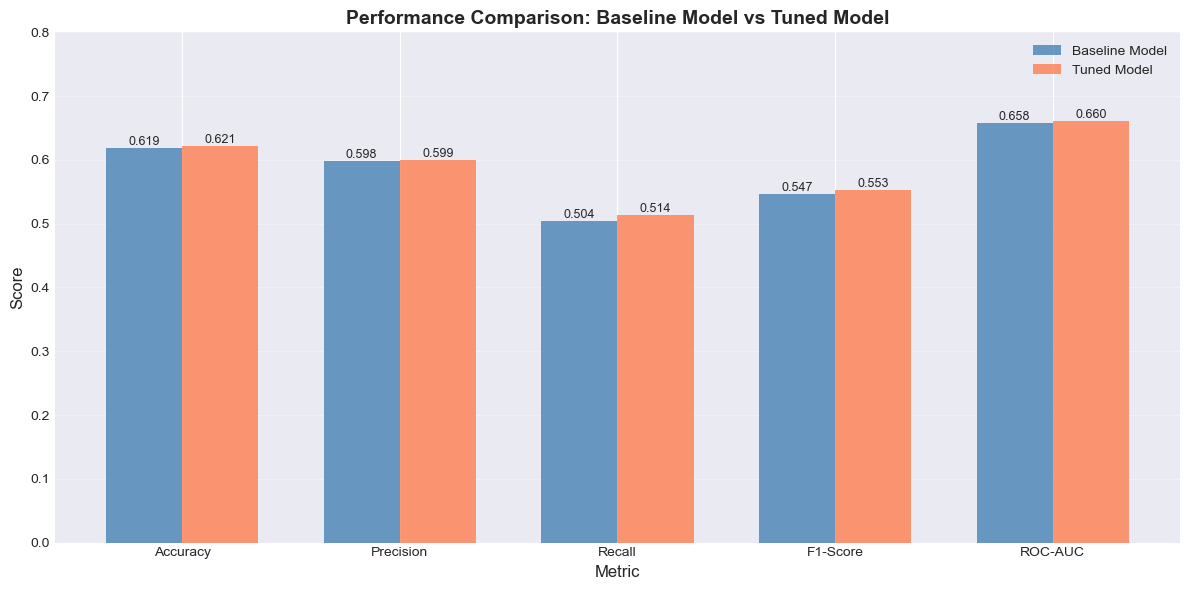

In [29]:
# Calculate metrics
test_metrics_base = calculate_metrics(y_test, y_pred_test, y_pred_proba_test)
test_metrics_tuned = calculate_metrics(y_test, y_pred_test_tuned, y_pred_proba_test_tuned)

# Compare two metrics
compare_two_models(test_metrics_base, test_metrics_tuned, "Baseline Model", "Tuned Model")

In [30]:
# Classification Report Baseline
print("Baseline: Classification Report (Test Set):")
print(classification_report(y_test, y_pred_test, target_names=['Not Readmitted', 'Readmitted']))

# Classification Report Tuned Model
print("\nTuned Model: Classification Report (Test Set):")
print(classification_report(y_test, y_pred_test_tuned, target_names=['Not Readmitted', 'Readmitted']))

Baseline: Classification Report (Test Set):
                precision    recall  f1-score   support

Not Readmitted       0.63      0.72      0.67      2718
    Readmitted       0.60      0.50      0.55      2282

      accuracy                           0.62      5000
     macro avg       0.62      0.61      0.61      5000
  weighted avg       0.62      0.62      0.61      5000


Tuned Model: Classification Report (Test Set):
                precision    recall  f1-score   support

Not Readmitted       0.64      0.71      0.67      2718
    Readmitted       0.60      0.51      0.55      2282

      accuracy                           0.62      5000
     macro avg       0.62      0.61      0.61      5000
  weighted avg       0.62      0.62      0.62      5000



In [31]:
def visualize_matrices(cm_1, cm_2, title_1="Model 1", title_2="Model 2"):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    sns.heatmap(cm_1, annot=True, fmt='d', cmap='Blues', cbar=True, ax=axes[0],
                xticklabels=['Not Readmitted', 'Readmitted'],
                yticklabels=['Not Readmitted', 'Readmitted'])
    axes[0].set_title(f'Confusion Matrix - {title_1}', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('True Label', fontsize=12)
    axes[0].set_xlabel('Predicted Label', fontsize=12)

    sns.heatmap(cm_2, annot=True, fmt='d', cmap='Blues', cbar=True, ax=axes[1],
                xticklabels=['Not Readmitted', 'Readmitted'],
                yticklabels=['Not Readmitted', 'Readmitted'])
    axes[1].set_title(f'Confusion Matrix - {title_2}', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('True Label', fontsize=12)
    axes[1].set_xlabel('Predicted Label', fontsize=12)

    plt.tight_layout()
    plt.show()

    tn_1, fp_1, fn_1, tp_1 = cm_1.ravel()
    tn_2, fp_2, fn_2, tp_2 = cm_2.ravel()
    print(f"\nTrue Negatives (Correctly predicted NOT readmitted): {tn_1} vs. {tn_2}")
    print(f"True Positives (Correctly predicted readmitted): {tp_1} vs. {tp_2}")
    print(f"False Positives (Incorrectly predicted readmitted): {fp_1} vs. {fp_2}")
    print(f"False Negatives (Incorrectly predicted NOT readmitted): {fn_1} vs. {fn_2}")


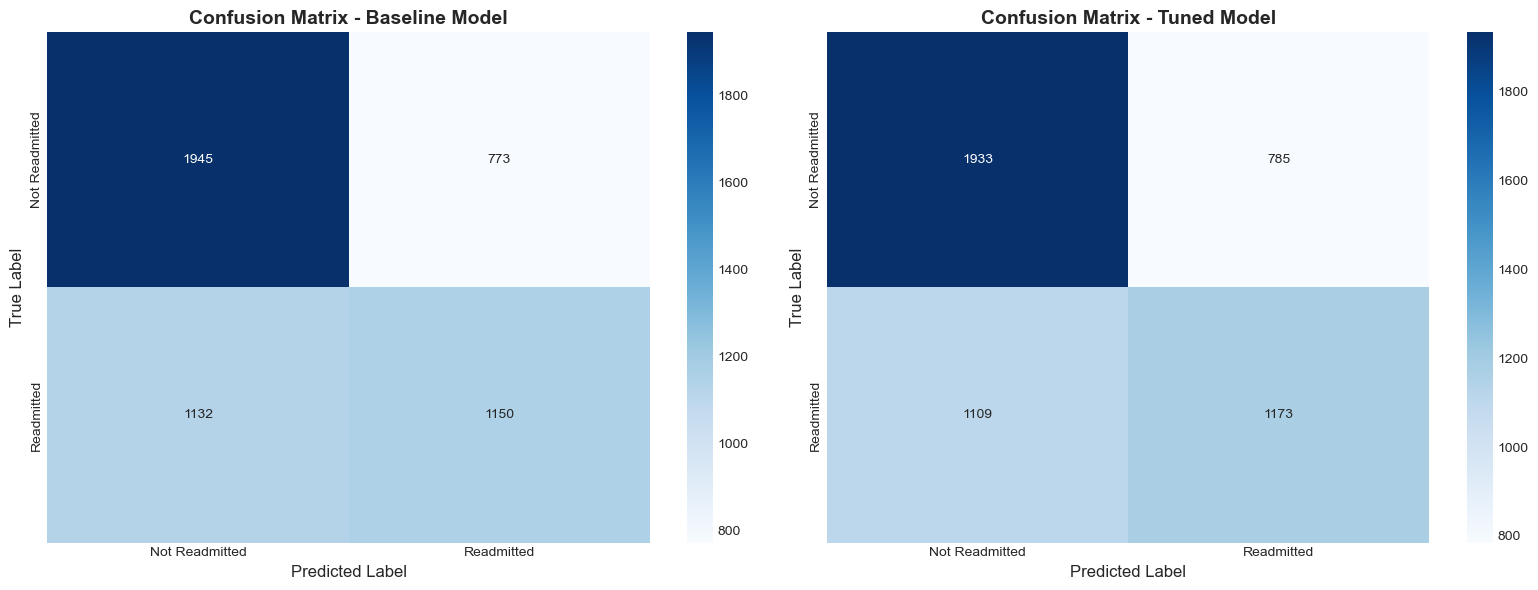


True Negatives (Correctly predicted NOT readmitted): 1945 vs. 1933
True Positives (Correctly predicted readmitted): 1150 vs. 1173
False Positives (Incorrectly predicted readmitted): 773 vs. 785
False Negatives (Incorrectly predicted NOT readmitted): 1132 vs. 1109


In [32]:
# Create confusion matrix
cm_base = confusion_matrix(y_test, y_pred_test)
cm_tuned = confusion_matrix(y_test, y_pred_test_tuned)

visualize_matrices(cm_base, cm_tuned, "Baseline Model", "Tuned Model")

## 7. XAI Analysis

### 7.1 Permutation Importance (eli5)

Measures how much model performance drops when a feature's values are randomly shuffled. A large drop indicates high feature importance.

In [33]:
# Calculate Permutation Importance using eli5
print("Calculating Permutation Importance (this may take a moment)...")
perm = PermutationImportance(model_tuned, random_state=42, n_iter=10)
perm.fit(X_test, y_test)
print("Permutation Importance calculated")

Calculating Permutation Importance (this may take a moment)...
Permutation Importance calculated


In [34]:
# Display top 20 most important features
feature_importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': perm.feature_importances_,
    'std': perm.feature_importances_std_
}).sort_values('importance', ascending=False)

print("\nTop 20 Features by Permutation Importance (eli5):")
print("=" * 70)
display(feature_importance_df.head(20))


Top 20 Features by Permutation Importance (eli5):


,feature,importance,std
49,total_utilization,0.02966,0.002661
6,number_inpatient,0.01596,0.001819
1,num_lab_procedures,0.00550,0.002807
26,diag_1_428,0.00462,0.001631
12,age_60-70,0.00322,0.001133
3,num_medications,0.00314,0.003447
51,labs_per_day,0.00306,0.002301
7,number_diagnoses,0.00288,0.002286
24,medical_specialty_Family/GeneralPractice,0.00282,0.000910
39,metformin_No,0.00272,0.002052


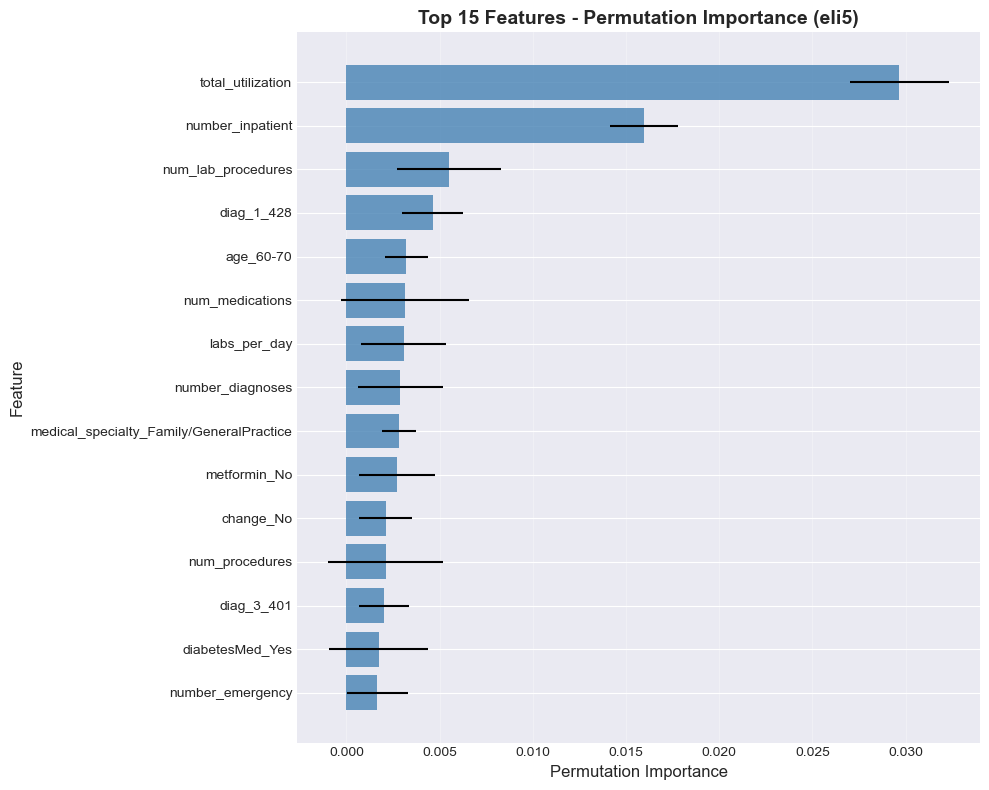

In [35]:
# Visualize top 15 features
top_n = 15
top_features = feature_importance_df.head(top_n)

plt.figure(figsize=(10, 8))
plt.barh(range(top_n), top_features['importance'], 
         xerr=top_features['std'], color='steelblue', alpha=0.8)
plt.yticks(range(top_n), top_features['feature'])
plt.xlabel('Permutation Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.title('Top 15 Features - Permutation Importance (eli5)', 
          fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 7.2 SHAP (SHapley Additive exPlanations)

SHAP values decompose each individual prediction into feature contributions, providing both global importance rankings and local explanations for single predictions.

#### 7.2.1 Initialize SHAP Explainer

In [36]:
# Create SHAP TreeExplainer (optimized for XGBoost)
print("Initializing SHAP TreeExplainer...")
explainer = shap.TreeExplainer(model_tuned)
print("SHAP Explainer initialized")

# Calculate SHAP values for test set
print("\nCalculating SHAP values for test set (this may take a moment)...")
shap_values = explainer.shap_values(X_test)
print("SHAP values calculated")

Initializing SHAP TreeExplainer...
SHAP Explainer initialized

Calculating SHAP values for test set (this may take a moment)...
SHAP values calculated


#### 7.2.2 Global Explanation: Summary Plot

The summary plot shows the most important features and their impact on predictions across all samples.

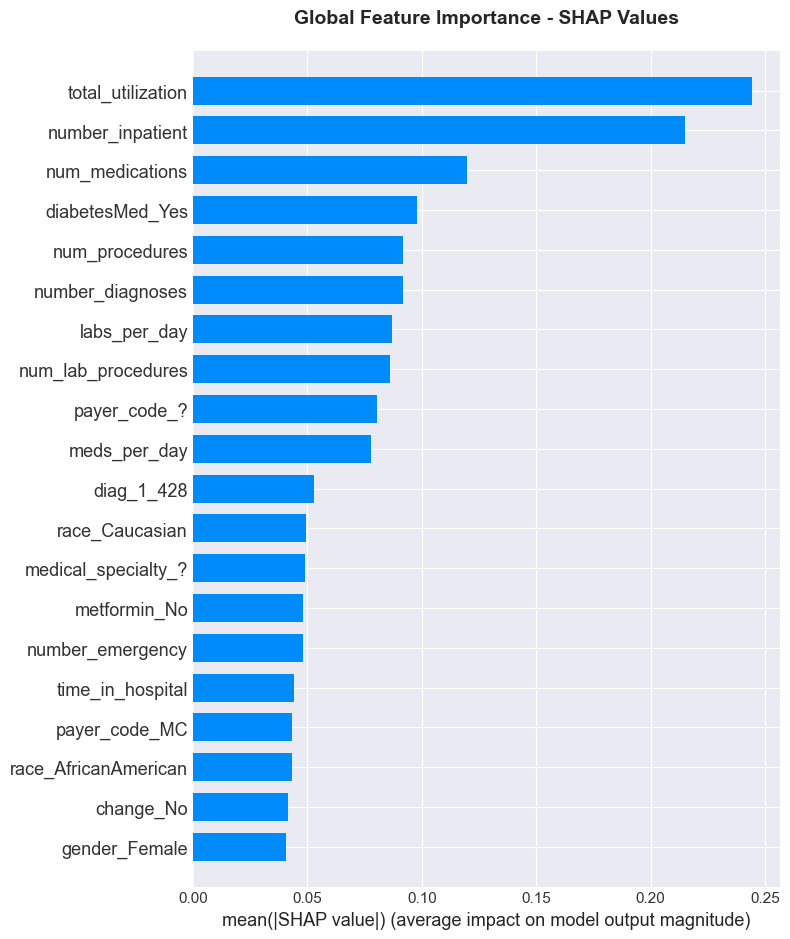

In [37]:
# SHAP Summary Plot (global feature importance)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title('Global Feature Importance - SHAP Values', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

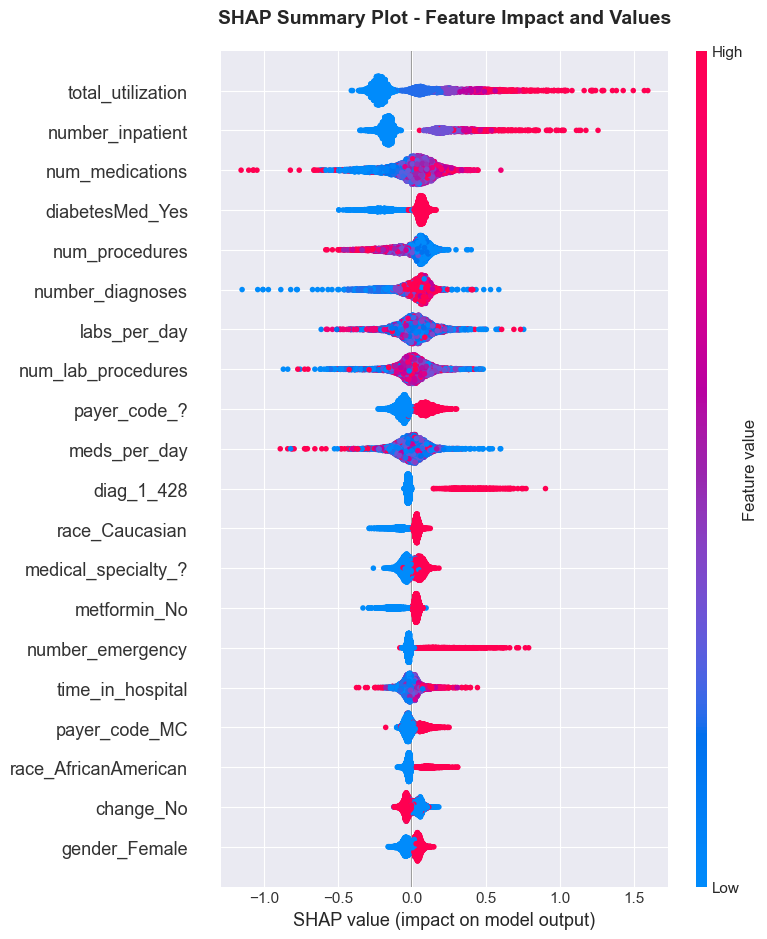


Interpretation:
- Each dot represents a sample
- Red = High feature value, Blue = Low feature value
- Position on x-axis shows impact on prediction (right = increases readmission risk)


In [38]:
# Detailed SHAP Summary Plot (shows feature values and impact direction)
plt.figure(figsize=(10, 10))
shap.summary_plot(shap_values, X_test, show=False, max_display=20)
plt.title('SHAP Summary Plot - Feature Impact and Values', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("- Each dot represents a sample")
print("- Red = High feature value, Blue = Low feature value")
print("- Position on x-axis shows impact on prediction (right = increases readmission risk)")

#### 7.2.3 Local Explanations: Force Plots

Force plots show how features contribute to individual predictions.

In [39]:
# Initialize JavaScript for interactive plots
shap.initjs()

# Select interesting samples for explanation
# 1. High-confidence positive prediction (high risk of readmission)
high_risk_idx = y_pred_proba_test.argsort()[-1]
print(f"Sample 1: High readmission risk (probability: {y_pred_proba_test[high_risk_idx]:.3f})")

# 2. High-confidence negative prediction (low risk)
low_risk_idx = y_pred_proba_test.argsort()[0]
print(f"Sample 2: Low readmission risk (probability: {y_pred_proba_test[low_risk_idx]:.3f})")

# 3. Borderline case
borderline_idx = (np.abs(y_pred_proba_test - 0.5)).argsort()[0]
print(f"Sample 3: Borderline case (probability: {y_pred_proba_test[borderline_idx]:.3f})")

Sample 1: High readmission risk (probability: 0.972)
Sample 2: Low readmission risk (probability: 0.042)
Sample 3: Borderline case (probability: 0.500)



=== Force Plot: High Readmission Risk Patient ===


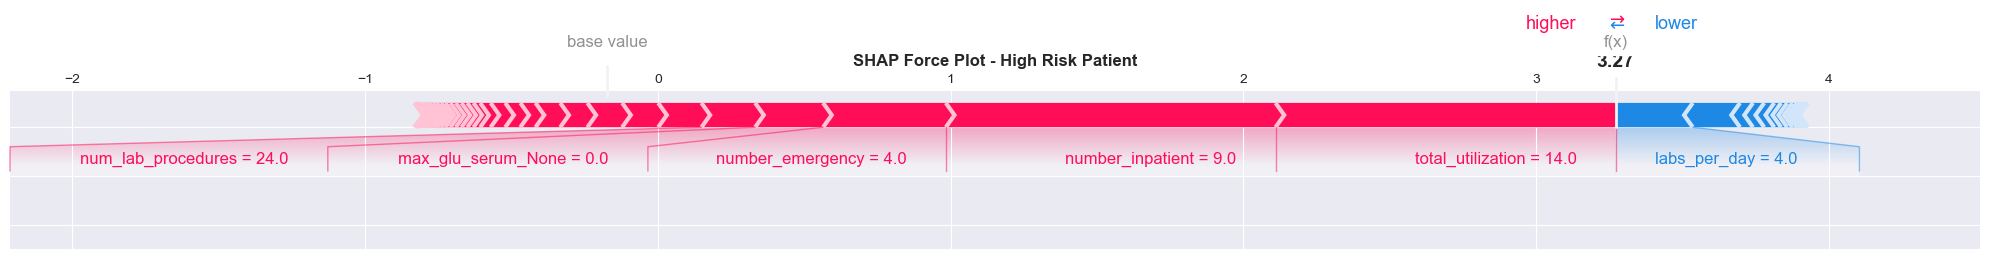

In [40]:
# Force plot for high-risk patient
print("\n=== Force Plot: High Readmission Risk Patient ===")
shap.force_plot(
    explainer.expected_value,
    shap_values[high_risk_idx],
    X_test.iloc[high_risk_idx],
    matplotlib=True,
    show=False
)
plt.title('SHAP Force Plot - High Risk Patient', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


=== Force Plot: Low Readmission Risk Patient ===


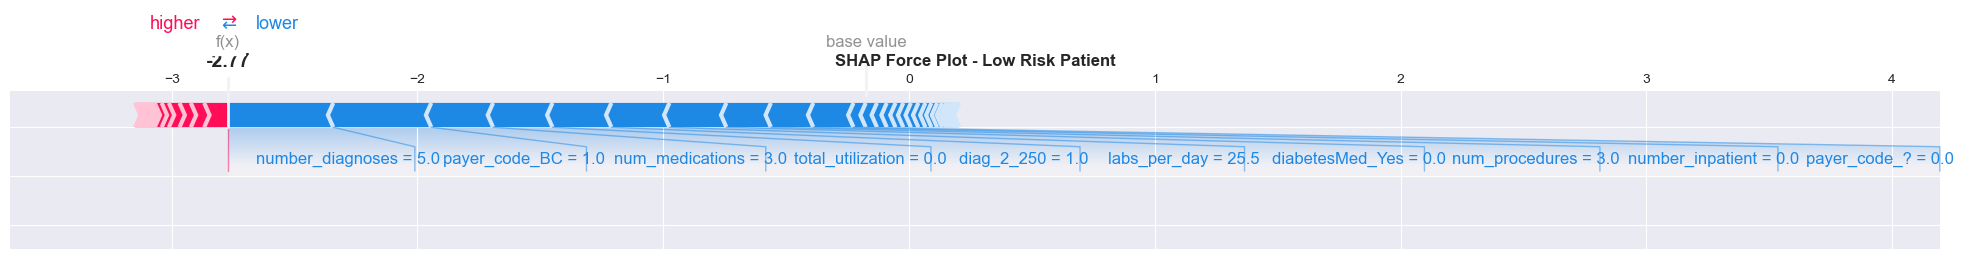

In [41]:
# Force plot for low-risk patient
print("\n=== Force Plot: Low Readmission Risk Patient ===")
shap.force_plot(
    explainer.expected_value,
    shap_values[low_risk_idx],
    X_test.iloc[low_risk_idx],
    matplotlib=True,
    show=False
)
plt.title('SHAP Force Plot - Low Risk Patient', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


=== Force Plot: Borderline Case ===


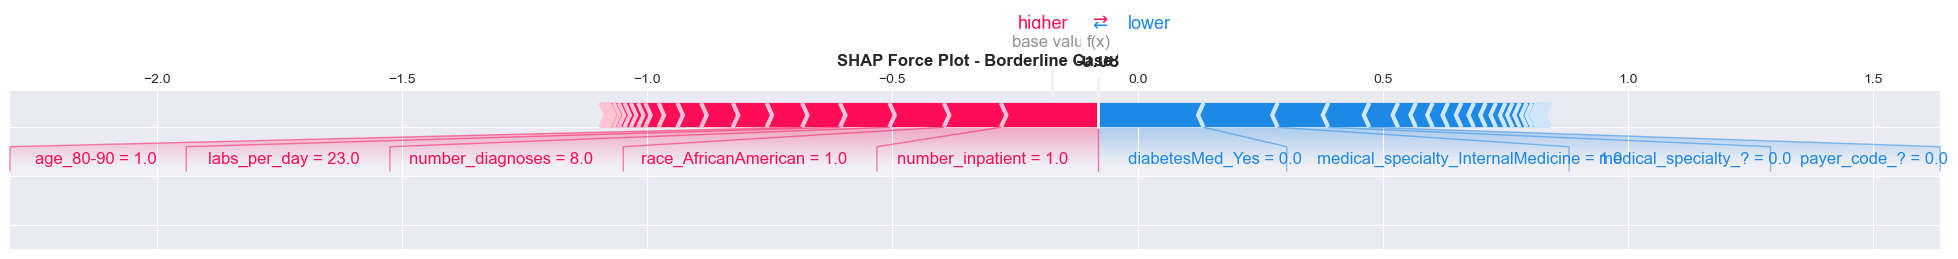

In [42]:
# Force plot for borderline case
print("\n=== Force Plot: Borderline Case ===")
shap.force_plot(
    explainer.expected_value,
    shap_values[borderline_idx],
    X_test.iloc[borderline_idx],
    matplotlib=True,
    show=False
)
plt.title('SHAP Force Plot - Borderline Case', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

#### 7.2.4 Dependence Plots

Show how feature values affect predictions and interactions with other features.

Top 6 features by SHAP importance: ['number_diagnoses', 'num_procedures', 'diabetesMed_Yes', 'num_medications', 'number_inpatient', 'total_utilization']


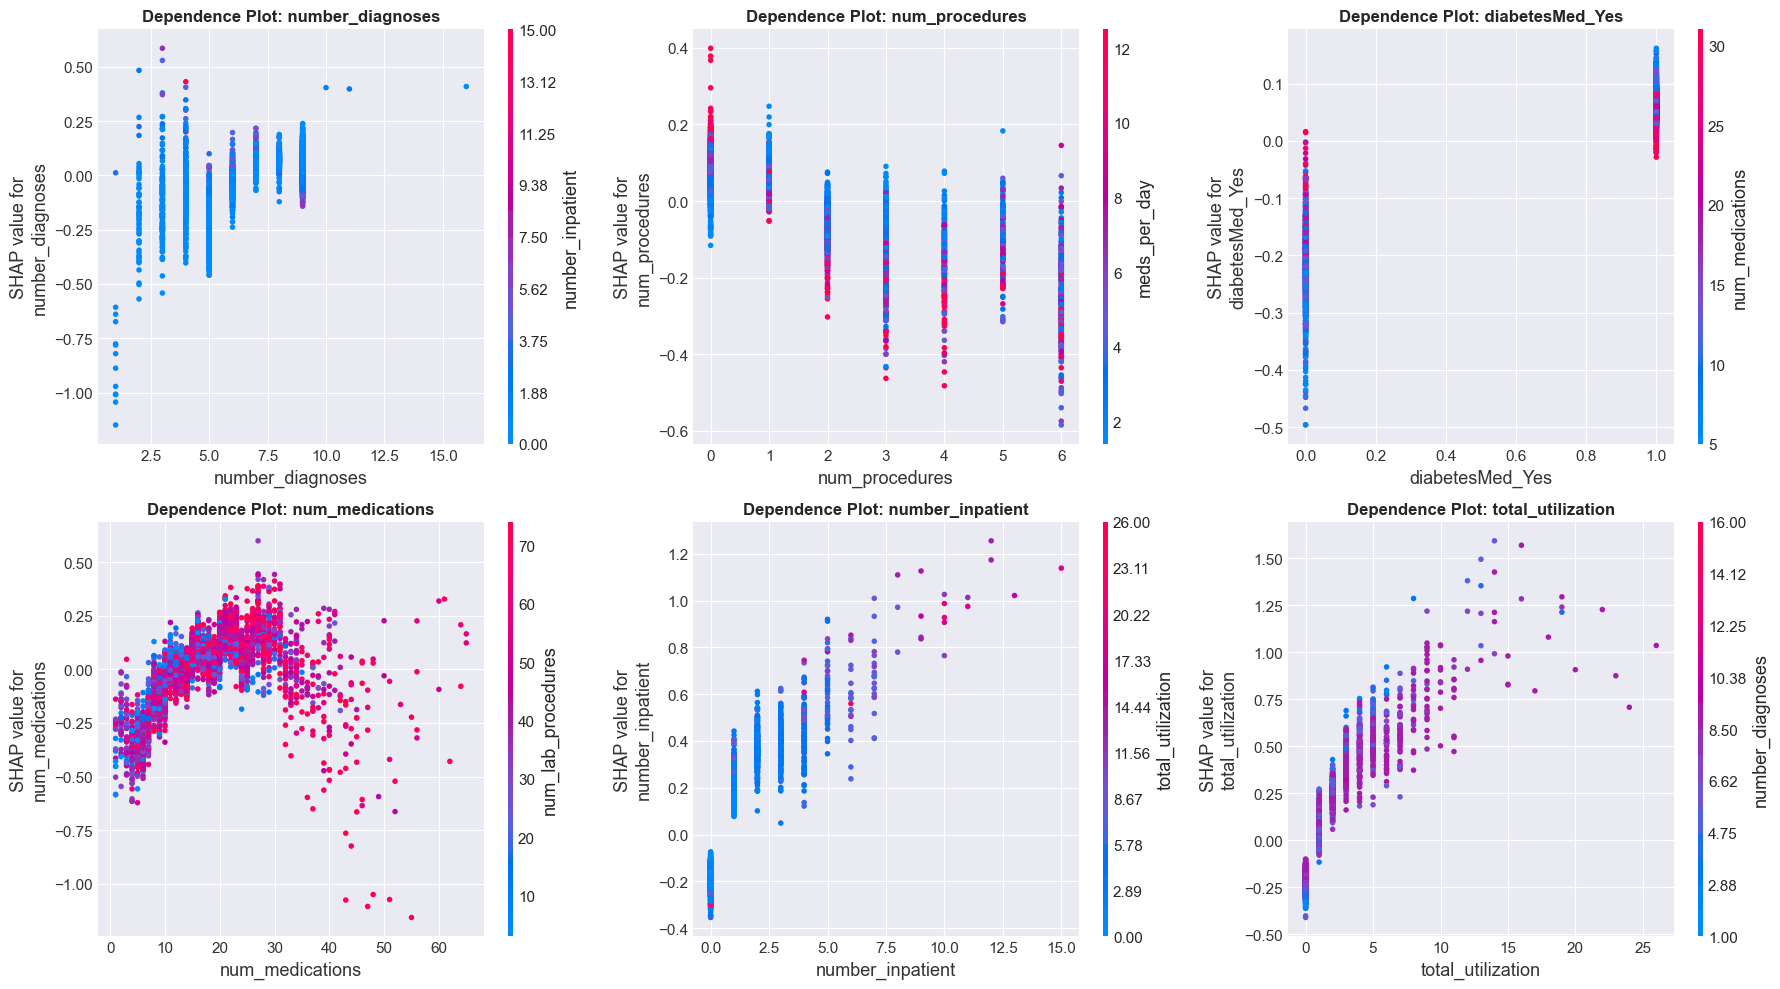

In [43]:
# Get top 6 most important features from SHAP
shap_importance = np.abs(shap_values).mean(axis=0)
top_6_features = X_test.columns[np.argsort(shap_importance)[-6:]]

print(f"Top 6 features by SHAP importance: {list(top_6_features)}")

# Create dependence plots for top 6 features (2 rows x 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()  # Convert 2D array to 1D for easier iteration

for idx, feature in enumerate(top_6_features):
    plt.sca(axes[idx])
    shap.dependence_plot(
        feature, 
        shap_values, 
        X_test, 
        show=False,
        ax=axes[idx]
    )
    axes[idx].set_title(f'Dependence Plot: {feature}', fontweight='bold')

plt.tight_layout()
plt.show()

### 7.3 XAI Comparison: eli5 vs SHAP Feature Importance

In [44]:
# Extract SHAP feature importance
shap_importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'shap_importance': np.abs(shap_values).mean(axis=0)
}).sort_values('shap_importance', ascending=False)

# Merge with eli5 importance
comparison_df = feature_importance_df[['feature', 'importance']].copy()
comparison_df.columns = ['feature', 'eli5_importance']
comparison_df = comparison_df.merge(shap_importance_df, on='feature')

# Normalize both for comparison
comparison_df['eli5_normalized'] = (comparison_df['eli5_importance'] - comparison_df['eli5_importance'].min()) / (comparison_df['eli5_importance'].max() - comparison_df['eli5_importance'].min())
comparison_df['shap_normalized'] = (comparison_df['shap_importance'] - comparison_df['shap_importance'].min()) / (comparison_df['shap_importance'].max() - comparison_df['shap_importance'].min())

# Display top 15 by average
comparison_df['average'] = (comparison_df['eli5_normalized'] + comparison_df['shap_normalized']) / 2
comparison_df = comparison_df.sort_values('average', ascending=False)

print("\nTop 15 Features - Comparison of eli5 and SHAP Importance:")
print("=" * 80)
display(comparison_df.head(15))


Top 15 Features - Comparison of eli5 and SHAP Importance:


,feature,eli5_importance,shap_importance,eli5_normalized,shap_normalized,average
0,total_utilization,0.02966,0.244073,1.000000,1.000000,1.000000
1,number_inpatient,0.01596,0.215171,0.571339,0.880346,0.725843
5,num_medications,0.00314,0.119621,0.170213,0.484765,0.327489
2,num_lab_procedures,0.00550,0.086157,0.244055,0.346224,0.295140
7,number_diagnoses,0.00288,0.091684,0.162078,0.369104,0.265591
13,diabetesMed_Yes,0.00172,0.097936,0.125782,0.394990,0.260386
6,labs_per_day,0.00306,0.087051,0.167710,0.349923,0.258816
11,num_procedures,0.00210,0.091803,0.137672,0.369597,0.253635
3,diag_1_428,0.00462,0.052817,0.216521,0.208195,0.212358
26,meds_per_day,0.00124,0.078000,0.110763,0.312452,0.211608


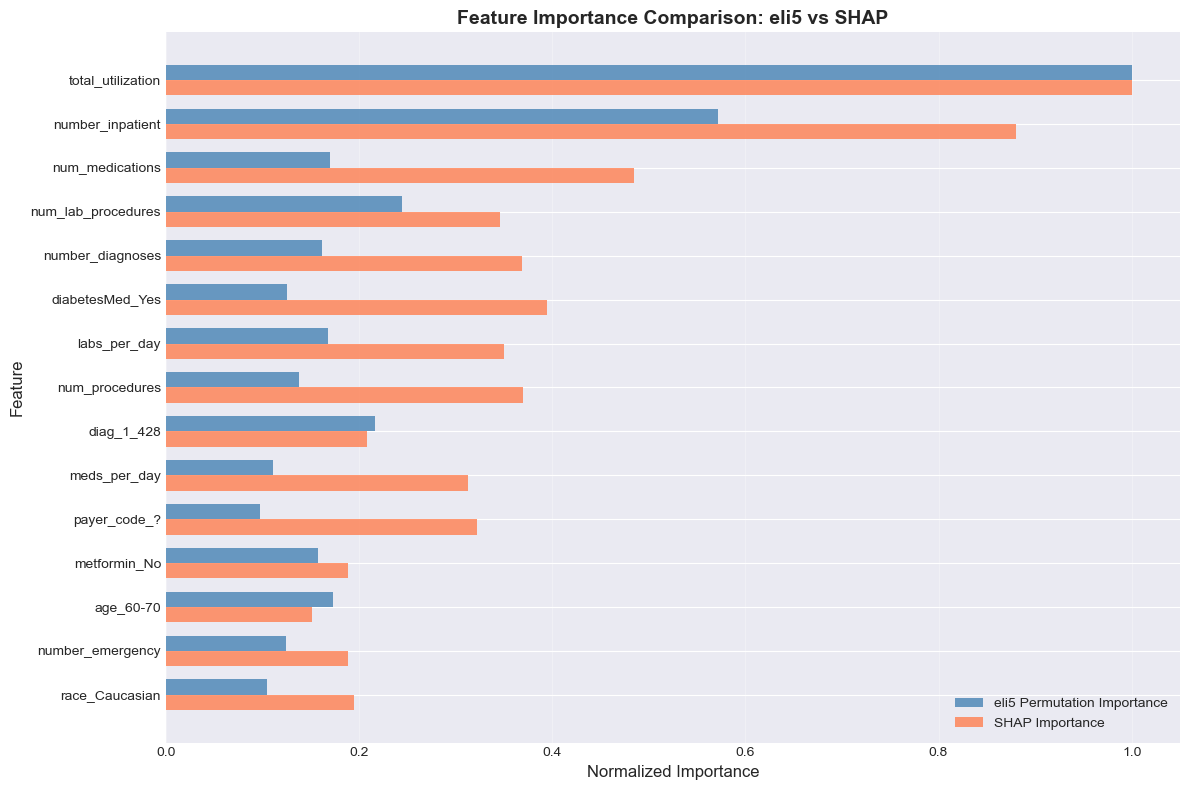

In [45]:
# Visualize comparison for top 15 features
top_15_comparison = comparison_df.head(15)

x = np.arange(len(top_15_comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(x - width/2, top_15_comparison['eli5_normalized'], width, 
        label='eli5 Permutation Importance', color='steelblue', alpha=0.8)
ax.barh(x + width/2, top_15_comparison['shap_normalized'], width, 
        label='SHAP Importance', color='coral', alpha=0.8)

ax.set_ylabel('Feature', fontsize=12)
ax.set_xlabel('Normalized Importance', fontsize=12)
ax.set_title('Feature Importance Comparison: eli5 vs SHAP', fontsize=14, fontweight='bold')
ax.set_yticks(x)
ax.set_yticklabels(top_15_comparison['feature'])
ax.legend()
ax.invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 8. XAI-Guided Feature Selection and Improved Model

### 8.1 Key Findings from XAI Analysis

**Dominant predictor**: `total_utilization` / `number_inpatient` dominates both methods. Patients with 0 prior admissions rarely get readmitted; patients with 5+ are almost always readmitted.

**Feature interactions** (from SHAP dependence plots):
- Emergency visits have stronger impact on older patients
- High medication count combined with many diagnoses indicates severe cases
- `number_emergency` shows a threshold effect: 0 → neutral, 1+ → sudden risk increase

**Local explanation patterns** (from force plots):
- High-risk patients are driven almost entirely by utilization history
- Low-risk patients are characterized by zero prior admissions
- Borderline cases show competing risk and protective factors

**Feature selection strategy**: Keep top 32 features ranked by averaged normalized eli5 and SHAP importance. This removes 20 low-impact features while maintaining predictive performance.

### 8.2 Train Improved Model: Feature-Selected XGBoost

Train a new model using only the most important features identified by XAI analysis.

#### 8.2.1 Select Top Features

In [46]:
# Select top features based on average of normalized eli5 and SHAP importance
top_n_features = 32
selected_features_list = comparison_df.head(top_n_features)['feature'].tolist()

print(f"Selected top {top_n_features} features:")
print("=" * 70)
for i, feat in enumerate(selected_features_list, 1):
    print(f"{i:2d}. {feat}")

# Create new training and test sets with selected features
X_train_selected = X_train[selected_features_list]
X_test_selected = X_test[selected_features_list]

print(f"\nOriginal feature count: {X_train.shape[1]}")
print(f"Selected feature count: {X_train_selected.shape[1]}")
print(f"Reduction: {X_train.shape[1] - X_train_selected.shape[1]} features removed")

Selected top 32 features:
 1. total_utilization
 2. number_inpatient
 3. num_medications
 4. num_lab_procedures
 5. number_diagnoses
 6. diabetesMed_Yes
 7. labs_per_day
 8. num_procedures
 9. diag_1_428
10. meds_per_day
11. payer_code_?
12. metformin_No
13. age_60-70
14. number_emergency
15. race_Caucasian
16. change_No
17. gender_Female
18. insulin_No
19. payer_code_MC
20. race_AfricanAmerican
21. age_70-80
22. diag_3_401
23. medical_specialty_?
24. age_80-90
25. medical_specialty_Emergency/Trauma
26. medical_specialty_Family/GeneralPractice
27. medical_specialty_InternalMedicine
28. A1Cresult_None
29. number_outpatient
30. time_in_hospital
31. diag_2_250
32. diag_1_414

Original feature count: 52
Selected feature count: 32
Reduction: 20 features removed


#### 8.2.2 Train Improved Model with Hyperparameter Tuning

In [47]:
# Tuning with same search space and settings as in 7.3 for fair comparison
random_search_improved = RandomizedSearchCV(
    XGBClassifier(random_state=42),
    param_distributions=param_distributions,
    n_iter=200,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_improved.fit(X_train_selected, y_train)

print(f"\nBest F1 Score (CV): {random_search_improved.best_score_:.4f}")
print(f"\nBest Parameters:")
for param, value in random_search_improved.best_params_.items():
    print(f"  {param}: {value}")

model_improved = random_search_improved.best_estimator_
print("\nImproved model trained successfully")


Fitting 3 folds for each of 200 candidates, totalling 600 fits

Best F1 Score (CV): 0.5578

Best Parameters:
  subsample: 0.9
  reg_lambda: 5.0
  reg_alpha: 1.0
  n_estimators: 300
  min_child_weight: 7
  max_depth: 8
  learning_rate: 0.05
  colsample_bytree: 0.6

Improved model trained successfully


#### 8.2.3 Evaluate Improved Model

In [48]:
# Make predictions with improved model
y_pred_train_improved = model_improved.predict(X_train_selected)
y_pred_test_improved = model_improved.predict(X_test_selected)
y_pred_proba_test_improved = model_improved.predict_proba(X_test_selected)[:, 1]

In [49]:
# Crossvalidation to check stability
cv_scores = cross_val_score(model_improved, X_train_selected, y_train, cv=5, scoring='f1')
print(f"5-Fold CV F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

5-Fold CV F1: 0.5578 (+/- 0.0093)


In [50]:
compare_train_test_performance(
    y_pred_train_improved,y_pred_test_improved, 
    y_pred_proba_test_improved, y_train,y_test,"IMPROVED MODEL"
    )

IMPROVED MODEL

Metric          Training        Test           
------------------------------------------------------------
Accuracy        0.7758          0.6174         
Precision       0.7941          0.5945         
Recall          0.6867          0.5088         
F1-Score        0.7365          0.5483         
ROC-AUC         -               0.6567         




### 8.3 Performance Comparison: Tuned vs. XAI Improved Model


MODEL PERFORMANCE COMPARISON: TUNED MODEL vs XAI IMPROVED MODEL


,Metric,Tuned Model,XAI Improved Model,Difference,Change (%)
0,Accuracy,0.62,0.62,-0.00,-0.61
1,Precision,0.60,0.59,-0.00,-0.77
2,Recall,0.51,0.51,-0.01,-1.02
3,F1-Score,0.55,0.55,-0.01,-0.91
4,ROC-AUC,0.66,0.66,-0.00,-0.54


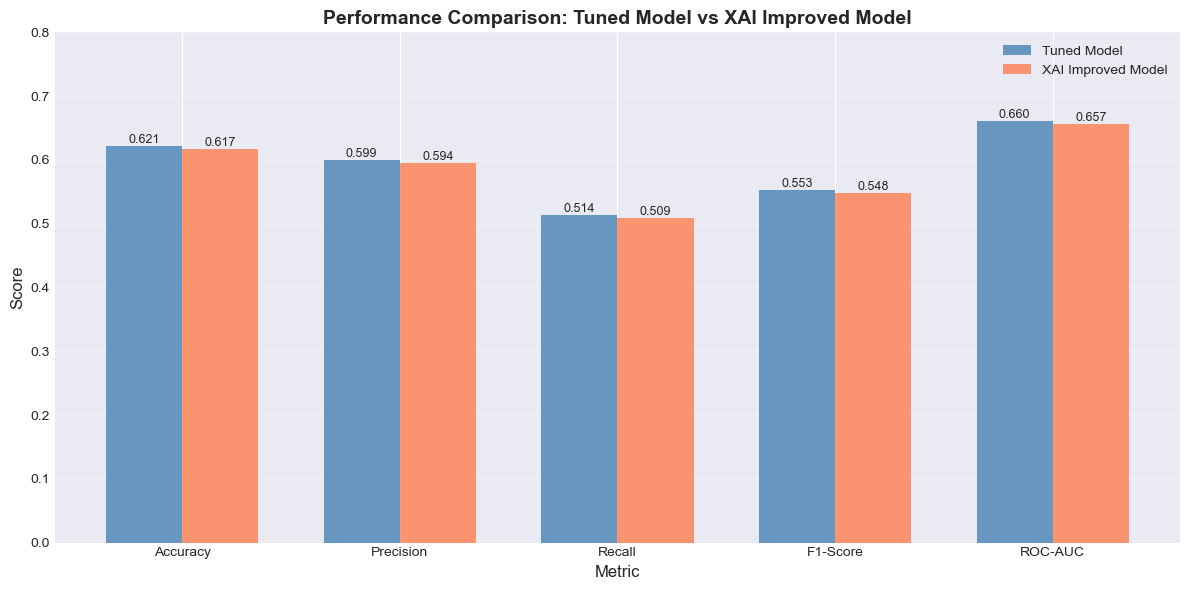

In [51]:
# Calculate metrics
test_metrics_tuned = calculate_metrics(y_test, y_pred_test_tuned, y_pred_proba_test_tuned)
test_metrics_improved = calculate_metrics(y_test, y_pred_test_improved, y_pred_proba_test_improved)

# Comparison of the metrics
compare_two_models(test_metrics_tuned, test_metrics_improved, "Tuned Model", "XAI Improved Model")

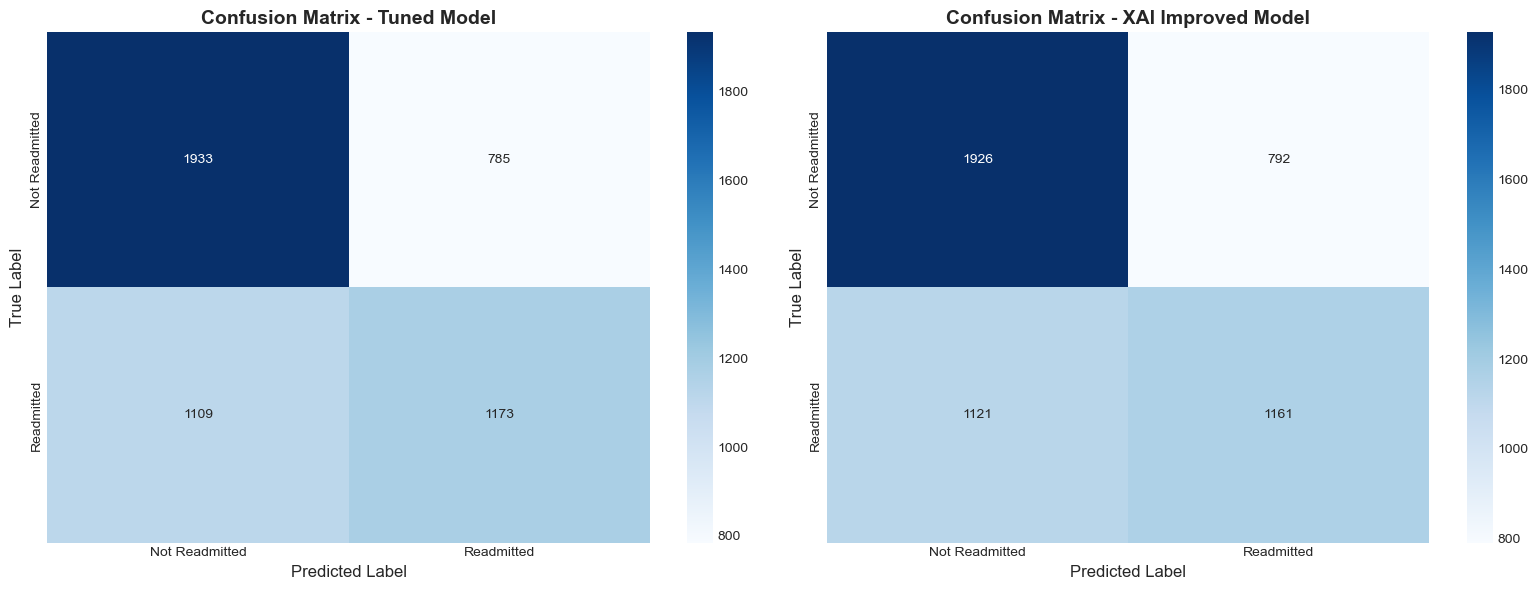


True Negatives (Correctly predicted NOT readmitted): 1933 vs. 1926
True Positives (Correctly predicted readmitted): 1173 vs. 1161
False Positives (Incorrectly predicted readmitted): 785 vs. 792
False Negatives (Incorrectly predicted NOT readmitted): 1109 vs. 1121


In [52]:
# Confusion matrix for improved model
cm_improved = confusion_matrix(y_test, y_pred_test_improved)

visualize_matrices(cm_tuned, cm_improved, "Tuned Model", "XAI Improved Model")

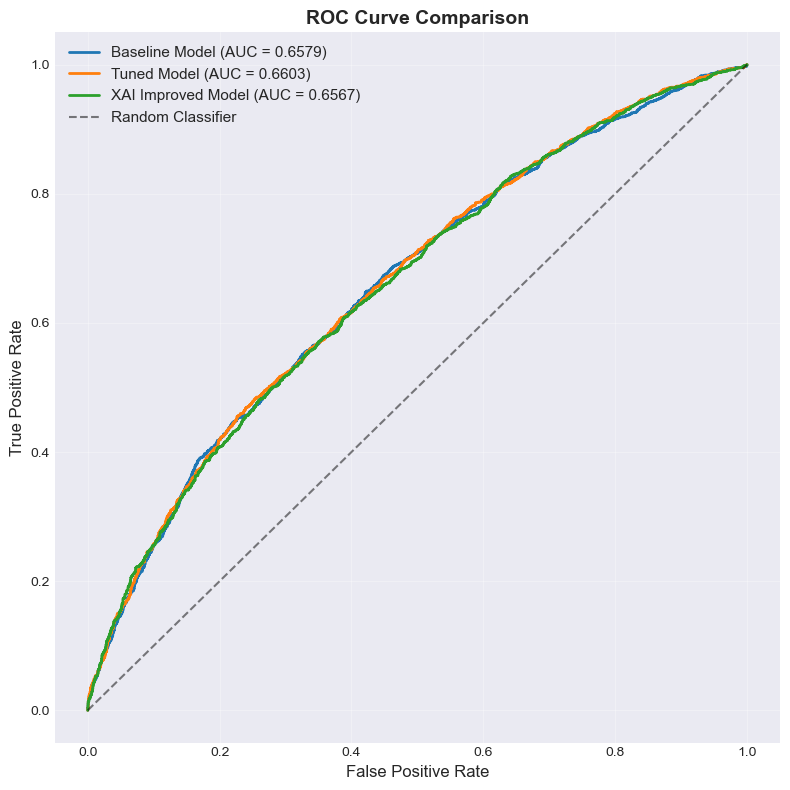

In [53]:
# ROC-AUC Curve for all three models

fig, ax = plt.subplots(figsize=(8, 8))

models = [
    ("Baseline Model", y_pred_proba_test),
    ("Tuned Model", y_pred_proba_test_tuned),
    ("XAI Improved Model", y_pred_proba_test_improved),
]

for name, y_proba in models:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})', linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve Comparison', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Conclusion

### Results
- **Baseline model** achieves ~62% accuracy and 0.66 ROC-AUC on test data
- **Hyperparameter tuning** reduced overfitting (train-test gap from ~20% to ~13%) with marginal test improvement
- **XAI-guided feature selection** maintained performance while reducing features by 38% (52 → 32), improving model interpretability

### XAI Method Comparison
- **eli5** and **SHAP** agree on the most important features, validating the findings
- **SHAP** provides richer insights through directional impact, feature interactions, and individual patient explanations
- Both methods confirm that healthcare utilization history is the dominant predictor of readmission

### Limitations
- Model performance (~62% accuracy, 0.66 AUC) reflects the inherent difficulty of readmission prediction — many driving factors (patient compliance, social environment) are not captured in the data
- Feature selection did not improve performance, only reduced complexity
- The dataset is pre-processed; original feature distributions and missing value patterns are unknown

### Potential Improvements
- Threshold tuning on the decision boundary to optimize for recall (clinically more relevant than accuracy)
- More extensive hyperparameter search or alternative models (LightGBM, ensemble stacking)
- Additional feature engineering based on SHAP interaction patterns
